# ECE 3715 Mini-Project 2
## Continuous Random Variables

**Christian Ruelas (Partner A): Steps 1 & 2**  
**Arun Nambiar (Partner B): Step 3 · Ibrahim Elsousi (Partner C)**  
**Seed: 1274601137 — drawn once on November 2, 2026; do not change.**

Steps 1 and 2 cover distribution and inversion experiments; Step 3 covers a function of a random variable.
Steps 4–8 remain pending. Each completed step contains derivations, numerical checks,
and a figure followed by an interpretation. Differences mean estimate minus theory.

In [1]:
from time import perf_counter
START = perf_counter()
from pathlib import Path
import sys
import numpy as np
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from mp2lib import (inv_cdf_exponential, inv_cdf_rayleigh,
                    sample_by_inversion, ks_statistic)

SEED = 1274601137  # drawn 2026-11-02, do not change
rng = np.random.default_rng(SEED)
# Create once here in this order. Reserve all later streams for the team.
rng1 = rng.spawn(1)[0]
rng2 = rng.spawn(1)[0]
rng3 = rng.spawn(1)[0]
rng4 = rng.spawn(1)[0]
rng5 = rng.spawn(1)[0]
rng6 = rng.spawn(1)[0]
rng7 = rng.spawn(1)[0]
rng8 = rng.spawn(1)[0]

FIGDIR = Path('figures')
FIGDIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'font.size': 10,
                     'axes.grid': True, 'grid.alpha': .22, 'axes.spines.top': False})

def table(headers, rows):
    def fmt(x):
        return f'{x:.7g}' if isinstance(x, (float, np.floating)) else str(x)
    display(Markdown('| ' + ' | '.join(headers) + ' |\n|' +
                     '|'.join(['---'] * len(headers)) + '|\n' +
                     '\n'.join('| ' + ' | '.join(fmt(x) for x in row) + ' |' for row in rows)))

def finish(fig, name):
    fig.savefig(FIGDIR / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

print(f'Seed: {SEED}')
print(f'Python {sys.version.split()[0]}, NumPy {np.__version__}, '
      f'SciPy {scipy.__version__}, Matplotlib {matplotlib.__version__}')

Seed: 1274601137
Python 3.13.18, NumPy 2.5.3, SciPy 1.18.1, Matplotlib 3.11.2


### Helper checks
Check the inverse endpoints, non-unit parameters, and a tiny positive uniform input.
Cross-check the custom KS statistic against SciPy, including tied observations,
to verify that both sides of each empirical-CDF jump are measured.
These checks consume none of the eight simulation streams.

In [2]:
assert inv_cdf_exponential(0, 2) == 0
assert inv_cdf_rayleigh(0, 3) == 0
assert np.isposinf(inv_cdf_exponential(1, 2))
assert np.isposinf(inv_cdf_rayleigh(1, 3))
u_check = np.array([0., 1e-16, .25, .75, np.nextafter(1., 0.)])
assert np.allclose(inv_cdf_exponential(u_check, 2), stats.expon.ppf(u_check, scale=.5))
assert np.allclose(inv_cdf_rayleigh(u_check, 3), stats.rayleigh.ppf(u_check, scale=3))
assert inv_cdf_exponential(1e-16, 1) > 0
for x_check in [np.array([.1, .4, .9]), np.array([.2, .2, .8]), np.array([.6])]:
    assert np.isclose(ks_statistic(x_check, stats.uniform.cdf),
                      stats.kstest(x_check, stats.uniform.cdf).statistic)
print('Inverse-CDF endpoint/parameter checks and KS cross-checks passed.')

Inverse-CDF endpoint/parameter checks and KS cross-checks passed.


## Step 1 — From CDF to density

For a continuous random variable, $F(x)=P(X\leq x)$ and $f(x)=F'(x)$ wherever
the derivative exists. Values assigned to a density at individual endpoints do not affect probabilities.

**Uniform on $[0,1]$ (support $[0,1]$):**
$$F(x)=\begin{cases}0&x<0\\x&0\leq x\leq1\\1&x>1,\end{cases}
\qquad f(x)=\begin{cases}1&0\leq x\leq1\\0&\text{otherwise}.\end{cases}$$

**Exponential with rate $\lambda=1$ (support $[0,\infty)$):**
$$F(x)=\begin{cases}0&x<0\\1-e^{-\lambda x}&x\geq0,\end{cases}
\qquad f(x)=\begin{cases}\lambda e^{-\lambda x}&x\geq0\\0&x<0.\end{cases}$$

**Standard Gaussian (support $\mathbb R$):**
$$F(x)=\Phi(x)=\frac12\left[1+\operatorname{erf}\left(\frac{x}{\sqrt2}\right)\right],
\qquad f(x)=\frac{e^{-x^2/2}}{\sqrt{2\pi}}.$$

**Rayleigh with scale $\sigma=1$ (support $[0,\infty)$):**
$$F(x)=\begin{cases}0&x<0\\1-e^{-x^2/(2\sigma^2)}&x\geq0,\end{cases}
\qquad f(x)=\begin{cases}\dfrac{x}{\sigma^2}e^{-x^2/(2\sigma^2)}&x\geq0\\0&x<0.\end{cases}$$

Generate $N=10^5$ observations of each distribution with NumPy's library generators.
For sorted samples $x_{(i)}$, the two-sided KS statistic checks both sides of every jump:
$$D_N=\max_i\left\{\frac{i}{N}-F(x_{(i)}),\ F(x_{(i)})-\frac{i-1}{N}\right\}.$$
The approximate 95% critical value is $1.36/\sqrt{10^5}=0.0043007$.
A statistic below the cutoff means the test does not reject the specified distribution;
it does not prove the distributions are identical. Parameters here are specified, not fitted.

| Distribution | N | KS D | 95% cutoff | Decision |
|---|---|---|---|---|
| Uniform [0,1] | 100000 | 0.003370311 | 0.004300698 | Do not reject |
| Exponential, rate 1 | 100000 | 0.001765445 | 0.004300698 | Do not reject |
| Standard Gaussian | 100000 | 0.003454166 | 0.004300698 | Do not reject |
| Rayleigh, scale 1 | 100000 | 0.002428224 | 0.004300698 | Do not reject |

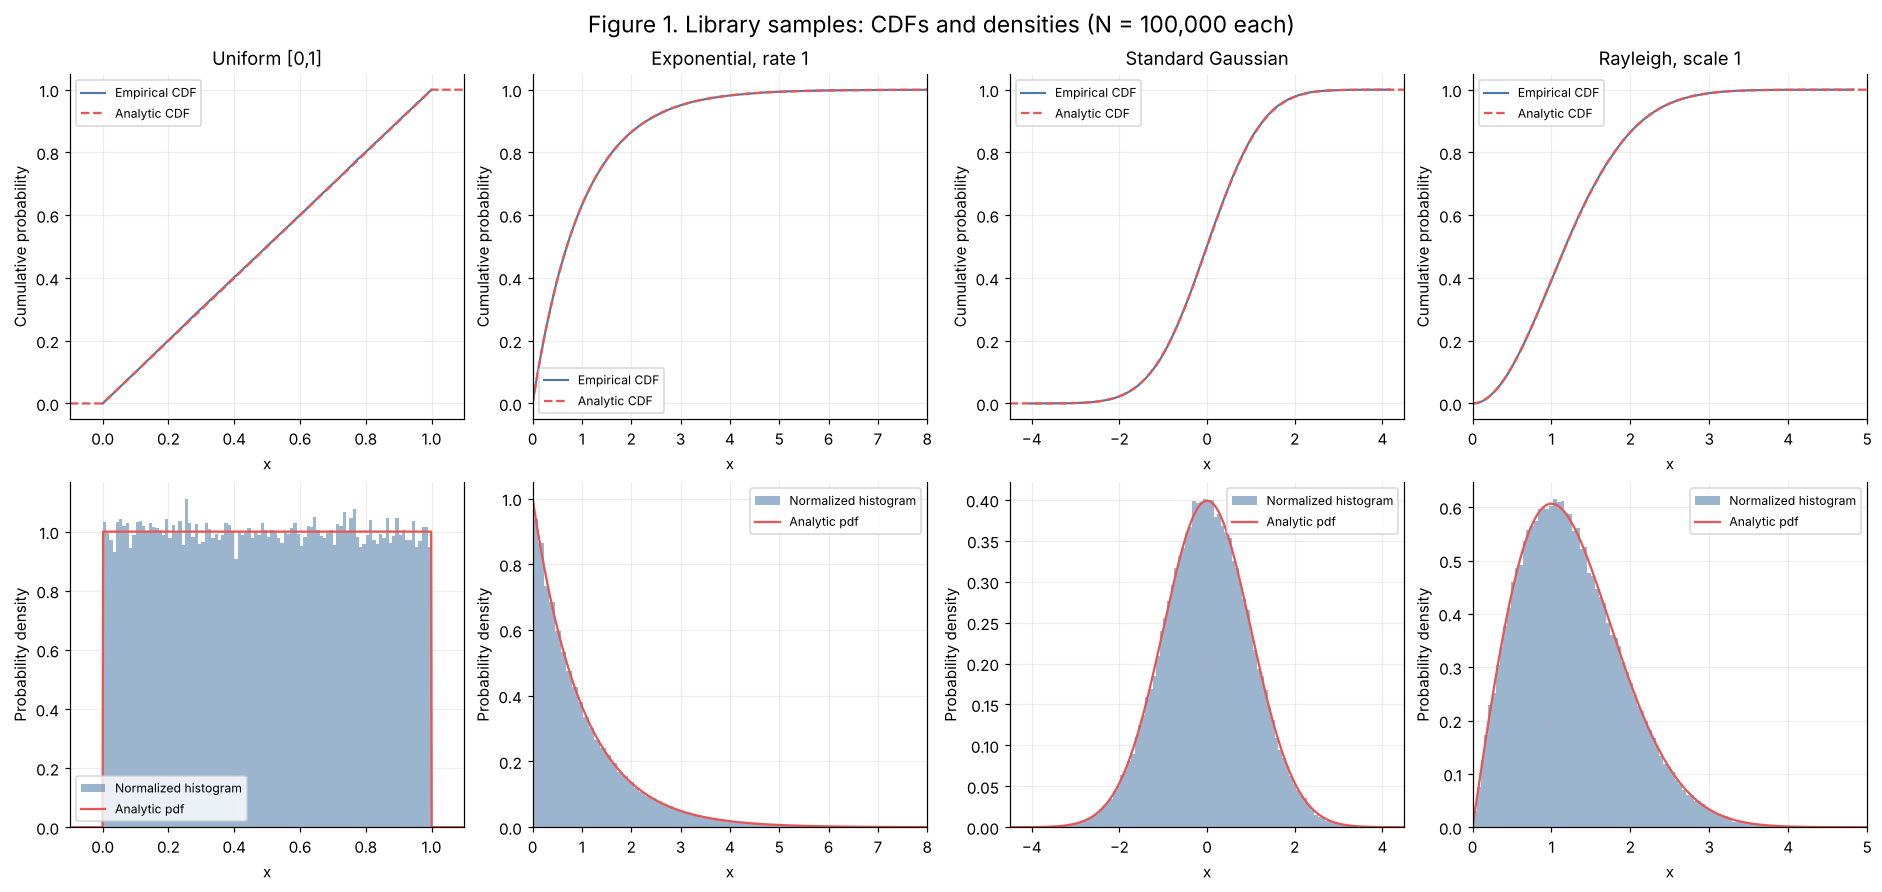

In [3]:
N1 = 100_000
critical1 = 1.36 / np.sqrt(N1)
distributions1 = [
    ('Uniform [0,1]', rng1.uniform(0, 1, N1), stats.uniform(), (-.1, 1.1)),
    ('Exponential, rate 1', rng1.exponential(1, N1), stats.expon(), (0, 8)),
    ('Standard Gaussian', rng1.standard_normal(N1), stats.norm(), (-4.5, 4.5)),
    ('Rayleigh, scale 1', rng1.rayleigh(1, N1), stats.rayleigh(), (0, 5)),
]
rows1 = []
fig, axes = plt.subplots(2, 4, figsize=(17, 8), layout='constrained')
for col, (name, samples, law, bounds) in enumerate(distributions1):
    d = ks_statistic(samples, law.cdf)
    rows1.append([name, N1, d, critical1, 'Do not reject' if d < critical1 else 'Reject'])
    x = np.linspace(*bounds, 700)
    ordered = np.sort(samples)
    axes[0, col].step(ordered, np.arange(1, N1 + 1) / N1, where='post',
                      lw=1.4, color='#4c78a8', label='Empirical CDF')
    axes[0, col].plot(x, law.cdf(x), '--', color='#e45756', label='Analytic CDF')
    axes[0, col].set(title=name, xlabel='x', ylabel='Cumulative probability', xlim=bounds)
    axes[0, col].legend(fontsize=8)
    axes[1, col].hist(samples, bins=100, density=True, color='#4c78a8', alpha=.55,
                      label='Normalized histogram')
    axes[1, col].plot(x, law.pdf(x), color='#e45756', label='Analytic pdf')
    axes[1, col].set(xlabel='x', ylabel='Probability density', xlim=bounds)
    axes[1, col].legend(fontsize=8)
fig.suptitle('Figure 1. Library samples: CDFs and densities (N = 100,000 each)', fontsize=15)
table(['Distribution', 'N', 'KS D', '95% cutoff', 'Decision'], rows1)
finish(fig, 'figure_01')

All four tests in Figure 1 do not reject their specified CDFs: the uniform, exponential, Gaussian, and Rayleigh KS distances are respectively **0.0033703, 0.0017654, 0.0034542, and 0.0024282**, each below the **0.0043007** cutoff at $N=10^5$.
The empirical and analytic curves are nearly superimposed at this scale, but visual overlap
alone cannot distinguish a small distributional error from sampling noise.
The exponential density peaks at the left boundary and has a long right tail;
the Rayleigh density starts at zero and rises to a mode at $x=1$.
The plotted windows focus on the bulk of the data; KS uses every observation and
the histograms are normalized using all observations, including the tails outside those windows.

### Exponential and Rayleigh moments

The six closed forms (with $\lambda=\sigma=1$ in this experiment) are

| Distribution | Mean | Median | Variance |
|---|---|---|---|
| Exponential | $1/\lambda=1$ | $\ln2/\lambda\approx0.693147$ | $1/\lambda^2=1$ |
| Rayleigh | $\sigma\sqrt{\pi/2}\approx1.253314$ | $\sigma\sqrt{2\ln2}\approx1.177410$ | $(2-\pi/2)\sigma^2\approx0.429204$ |

Use the arithmetic mean, sample median, and unbiased sample variance (`ddof=1`).
The exponential mean-to-median ratio is $1/\ln2\approx1.4427$ because its right-skewed density
has a long upper tail that pulls the mean above the point splitting the probability in half.
The Gaussian density is symmetric about zero, so its mean and median coincide at zero.

In [4]:
moment_rows1 = []
for index, theory in [(1, [1., np.log(2), 1.]),
                       (3, [np.sqrt(np.pi/2), np.sqrt(2*np.log(2)), 2-np.pi/2])]:
    name, samples, _, _ = distributions1[index]
    estimates = [np.mean(samples), np.median(samples), np.var(samples, ddof=1)]
    for quantity, estimate, exact in zip(['Mean', 'Median', 'Variance'], estimates, theory):
        moment_rows1.append([name, quantity, estimate, exact, estimate-exact])
table(['Distribution', 'Quantity', 'Estimate', 'Closed form', 'Difference'], moment_rows1)
print(f'Exponential theoretical mean/median = {1 / np.log(2):.7f}')

| Distribution | Quantity | Estimate | Closed form | Difference |
|---|---|---|---|---|
| Exponential, rate 1 | Mean | 1.00032 | 1 | 0.0003203091 |
| Exponential, rate 1 | Median | 0.6928037 | 0.6931472 | -0.000343495 |
| Exponential, rate 1 | Variance | 1.001347 | 1 | 0.001346822 |
| Rayleigh, scale 1 | Mean | 1.25254 | 1.253314 | -0.0007740946 |
| Rayleigh, scale 1 | Median | 1.175111 | 1.17741 | -0.002298586 |
| Rayleigh, scale 1 | Variance | 0.428195 | 0.4292037 | -0.001008695 |

Exponential theoretical mean/median = 1.4426950


## Step 2 — Build your own generator by inversion

### Inversion result and proof
Let $U\sim\operatorname{Uniform}(0,1)$ and let $F$ be continuous and strictly increasing
on its support. For $x$ in that support, monotonicity gives the two-line proof
$$P(F^{-1}(U)\leq x)=P(U\leq F(x)),$$
$$P(U\leq F(x))=F(x).$$
Outside the support the CDF is respectively zero or one, so the result extends to all real $x$.
The endpoint events have probability zero for an ideal continuous uniform variable.

### Derive the inverse CDFs
For the exponential distribution,
$$u=1-e^{-\lambda x}\ \Longrightarrow\ 1-u=e^{-\lambda x}
\ \Longrightarrow\ \ln(1-u)=-\lambda x
\ \Longrightarrow\ F^{-1}(u)=-\frac{\ln(1-u)}{\lambda}.$$
For the Rayleigh distribution,
$$u=1-e^{-x^2/(2\sigma^2)}\ \Longrightarrow\ \ln(1-u)=-\frac{x^2}{2\sigma^2}
\ \Longrightarrow\ x^2=-2\sigma^2\ln(1-u)
\ \Longrightarrow\ F^{-1}(u)=\sigma\sqrt{-2\ln(1-u)}.$$
The positive square root is required because Rayleigh samples are nonnegative.

### Endpoint and numerical handling
Both implementations use `log1p(-u)` to evaluate $\ln(1-u)$ accurately near zero.
Exactly $u=0$ maps to $x=0$, which belongs to both supports; no clipping or rejection is needed.
The inverse accepts $u=1$ and returns $+\infty$, the correct limiting quantile,
but `rng.random()` samples $[0,1)$ and therefore never supplies that endpoint.
Invalid probabilities and nonpositive or nonfinite parameters raise `ValueError`.
Both $-\ln(1-U)/\lambda$ and $-\ln U/\lambda$ have the same exponential distribution because
$1-U$ is also uniform in the continuous model; we use the first form so a returned zero stays finite.

### Verification plan
Use only `rng2.random()` through `sample_by_inversion` for the Step 2 samples.
Compare each inversion sample to its analytic CDF, then to the independent **Step 1 library
sample** with a two-sample KS test. This reuses the library reference without calling
`rng.exponential` or `rng.rayleigh` in Step 2. For two samples of sizes $n$ and $m$,
the approximate 95% cutoff is $1.36\sqrt{(n+m)/(nm)}=0.0060821$ when both are $10^5$.

| Distribution | N | Inversion KS D | 95% cutoff | Decision |
|---|---|---|---|---|
| Exponential, rate 1 | 100000 | 0.003825903 | 0.004300698 | Do not reject |
| Rayleigh, scale 1 | 100000 | 0.002079102 | 0.004300698 | Do not reject |

| Distribution | Library vs analytic D | Inversion vs library D | Two-sample cutoff | Two-sample decision |
|---|---|---|---|---|
| Exponential, rate 1 | 0.001765445 | 0.00425 | 0.006082105 | Do not reject |
| Rayleigh, scale 1 | 0.002428224 | 0.00417 | 0.006082105 | Do not reject |

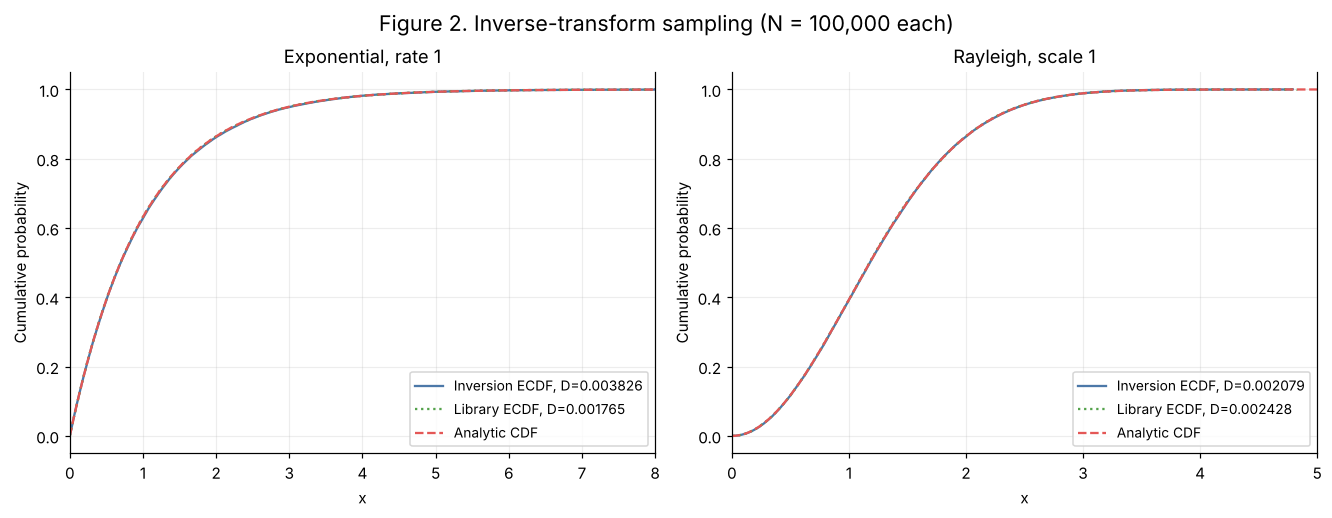

In [5]:
N2 = 100_000
critical2 = 1.36 / np.sqrt(N2)
inversion2 = [
    ('Exponential, rate 1', sample_by_inversion(inv_cdf_exponential, N2, rng2, lam=1),
     distributions1[1][1], stats.expon(), (0, 8)),
    ('Rayleigh, scale 1', sample_by_inversion(inv_cdf_rayleigh, N2, rng2, sigma=1),
     distributions1[3][1], stats.rayleigh(), (0, 5)),
]
rows2 = []
comparison_rows2 = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
for ax, (name, samples, reference, law, bounds) in zip(axes, inversion2):
    d = ks_statistic(samples, law.cdf)
    d_ref = ks_statistic(reference, law.cdf)
    d_two = stats.ks_2samp(samples, reference).statistic
    cutoff_two = 1.36 * np.sqrt((samples.size + reference.size) / (samples.size * reference.size))
    rows2.append([name, N2, d, critical2, 'Do not reject' if d < critical2 else 'Reject'])
    comparison_rows2.append([name, d_ref, d_two, cutoff_two,
                             'Do not reject' if d_two < cutoff_two else 'Reject'])
    ordered = np.sort(samples)
    ax.step(ordered, np.arange(1, N2 + 1) / N2, where='post', color='#4c78a8',
            label=f'Inversion ECDF, D={d:.6f}')
    ref_ordered = np.sort(reference)
    ax.step(ref_ordered, np.arange(1, reference.size + 1) / reference.size, where='post',
            color='#54a24b', ls=':', label=f'Library ECDF, D={d_ref:.6f}')
    x = np.linspace(*bounds, 700)
    ax.plot(x, law.cdf(x), '--', color='#e45756', label='Analytic CDF')
    ax.set(title=name, xlabel='x', ylabel='Cumulative probability', xlim=bounds)
    ax.legend(fontsize=9)
fig.suptitle('Figure 2. Inverse-transform sampling (N = 100,000 each)', fontsize=14)
table(['Distribution', 'N', 'Inversion KS D', '95% cutoff', 'Decision'], rows2)
table(['Distribution', 'Library vs analytic D', 'Inversion vs library D',
       'Two-sample cutoff', 'Two-sample decision'], comparison_rows2)
finish(fig, 'figure_02')

Figure 2 shows the inverse-transform ECDF alongside the analytic CDF and the independent
library ECDF. The first table compares inversion to the exact distribution and the second
compares the two sampling methods with the appropriate two-sample cutoff.
The test decisions apply to this frozen seed; a correctly implemented generator can still
exceed a 95% cutoff by chance, so the seed must never be redrawn to improve a result.
The Rayleigh square root spreads out small positive quantiles relative to the exponential,
consistent with its density vanishing at zero instead of peaking there.

For this run the exponential inversion gives **D = 0.0038259** and the Rayleigh inversion gives **D = 0.0020791**, both below **0.0043007**. Against independent library samples the two-sample distances are **0.0042500** and **0.0041700**, below **0.0060821**; neither test rejects at the approximate 5% level. These checks support the inverse formulas with numerical evidence rather than relying on the overlapping curves.

## Step 3 — A function of a random variable

### CDF of $Y=X^2$
Let $X\sim\mathcal N(0,1)$ with CDF $\Phi$ and density $\varphi$, and let $Y=X^2\geq 0$.
For $y\leq 0$, $F_Y(y)=0$ (and $F_Y(0)=P(X=0)=0$). For $y>0$, squaring is undone by a two-sided interval:
$$Y\leq y\iff X^2\leq y\iff -\sqrt y\leq X\leq\sqrt y.$$
$$F_Y(y)=P(-\sqrt y\leq X\leq\sqrt y)=\Phi(\sqrt y)-\Phi(-\sqrt y).$$
By symmetry $\Phi(-\sqrt y)=1-\Phi(\sqrt y)$, so
$$F_Y(y)=2\Phi(\sqrt y)-1,\qquad y>0.$$

### Density of $Y$
Differentiate with the chain rule, using $\Phi'=\varphi$ and $\frac{d}{dy}\sqrt y=\frac{1}{2\sqrt y}$:
$$f_Y(y)=\frac{d}{dy}\bigl[2\Phi(\sqrt y)-1\bigr]=2\varphi(\sqrt y)\cdot\frac{1}{2\sqrt y}=\frac{\varphi(\sqrt y)}{\sqrt y}.$$
Substituting $\varphi(\sqrt y)=e^{-y/2}/\sqrt{2\pi}$,
$$\boxed{f_Y(y)=\frac{1}{\sqrt{2\pi y}}\,e^{-y/2},\qquad y>0,}$$
and $f_Y(y)=0$ for $y<0$. This is the chi-square density with one degree of freedom.

### Why the density diverges but still integrates to 1
Near the origin $e^{-y/2}\to1$, so $f_Y(y)\approx(2\pi y)^{-1/2}\to\infty$ as $y\to0^+$.
The map $x\mapsto x^2$ has slope $2x\to0$ at the origin, so it is flat there:
a slab $|X|\leq\epsilon$ carries probability $\approx 2\epsilon\varphi(0)$ but lands in the thin interval
$0\leq Y\leq\epsilon^2$. Probability per unit length is therefore $\approx 2\epsilon\varphi(0)/\epsilon^2\propto 1/\epsilon=y^{-1/2}$, which grows without bound.
The total mass stays finite because $y^{-1/2}$ is integrable at zero:
$$P(Y\leq\delta)=\int_0^\delta\frac{dy}{\sqrt{2\pi y}}\,e^{-y/2}\approx\frac{2\sqrt\delta}{\sqrt{2\pi}}\to0\quad(\delta\to0),$$
and the exact value is $P(Y\leq\delta)=2\Phi(\sqrt\delta)-1\to0$. The same chain rule gives $\int_0^\infty f_Y=F_Y(\infty)-F_Y(0)=1$.

### Log-log slope
For small $y$, $\ln f_Y(y)\approx-\tfrac12\ln y-\tfrac12\ln(2\pi)$, a straight line of **slope $-1/2$** on log-log axes.
The exponent comes from the Jacobian $|dx/dy|=1/(2\sqrt y)$ of the inverse map $x=\sqrt y$.

### Analytic targets
$$P[Y\leq1]=2\Phi(1)-1,\qquad P[Y\leq0.1]=2\Phi(\sqrt{0.1})-1,\qquad m=\bigl(\Phi^{-1}(0.75)\bigr)^2,$$
since $2\Phi(\sqrt m)-1=\tfrac12\iff\Phi(\sqrt m)=0.75$. For the moments, $E[Y]=E[X^2]=1$ and
$$\operatorname{Var}(Y)=E[X^4]-(E[X^2])^2=3-1=2.$$
The fourth central moment of $Y$ is $E[(Y-1)^4]=60$ (chi-square, 1 degree of freedom), which gives the standard error of the sample variance, $\sqrt{(60-2^2)/N}$.
The median's standard error is $1/(2f_Y(m)\sqrt N)$.

### Verification plan
Draw $N=10^6$ standard Gaussians from `rng3`, square them, and compare the sample CDF with $F_Y$ using the KS statistic and the 95% cutoff $1.36/\sqrt N$.
**Binning choice:** log-spaced bins, 10 per decade from $10^{-6}$ to the sample maximum, because a uniform width of 0.5 puts the whole divergence in the first bar.
Histogram heights are counts divided by $N\times$(bin width), so they are densities; the $\approx 10^{-3}$ of samples below $10^{-6}$ still count in $N$.
The integral check uses `scipy.integrate.quad` with an algebraic endpoint weight $y^{-1/2}$ on $(0,1]$ to handle the singularity exactly, and the plain integrand on $[1,\infty)$.

Density integral: 0.6826894921 on (0,1] + 0.3173105079 on [1,inf) = 1.0000000000


| δ | Exact P(Y ≤ δ) | Approx 2√δ/√(2π) | f_Y(δ) |
|---|---|---|---|
| 0.1 | 0.2481704 | 0.2523133 | 1.200039 |
| 0.01 | 0.07965567 | 0.07978846 | 3.969525 |
| 0.0001 | 0.007978713 | 0.007978846 | 39.89223 |
| 1e-06 | 0.0007978844 | 0.0007978846 | 398.9421 |

| Test | N | KS D vs derived CDF | 95% cutoff | KS D vs scipy chi2(1) | Decision |
|---|---|---|---|---|---|
| Y = X² | 1000000 | 0.0009189483 | 0.00136 | 0.0009189483 | Do not reject |

| Quantity | Empirical | Theory | Difference | Std. error | Diff / SE |
|---|---|---|---|---|---|
| P[Y ≤ 1] | 0.682239 | 0.6826895 | -0.0004504921 | 0.0004654294 | -0.9679064 |
| P[Y ≤ 0.1] | 0.248191 | 0.2481704 | 2.063405e-05 | 0.0004319512 | 0.04776939 |
| Median | 0.4554059 | 0.4549364 | 0.0004695133 | 0.001061264 | 0.4424094 |
| Mean | 1.000613 | 1 | 0.0006133975 | 0.001414214 | 0.4337376 |
| Variance | 1.994066 | 2 | -0.005933742 | 0.007483315 | -0.7929297 |

| Log-log slope (y < 0.01) | Fitted | Theory | Difference |
|---|---|---|---|
| Histogram | -0.4959056 | -0.5 | 0.004094388 |

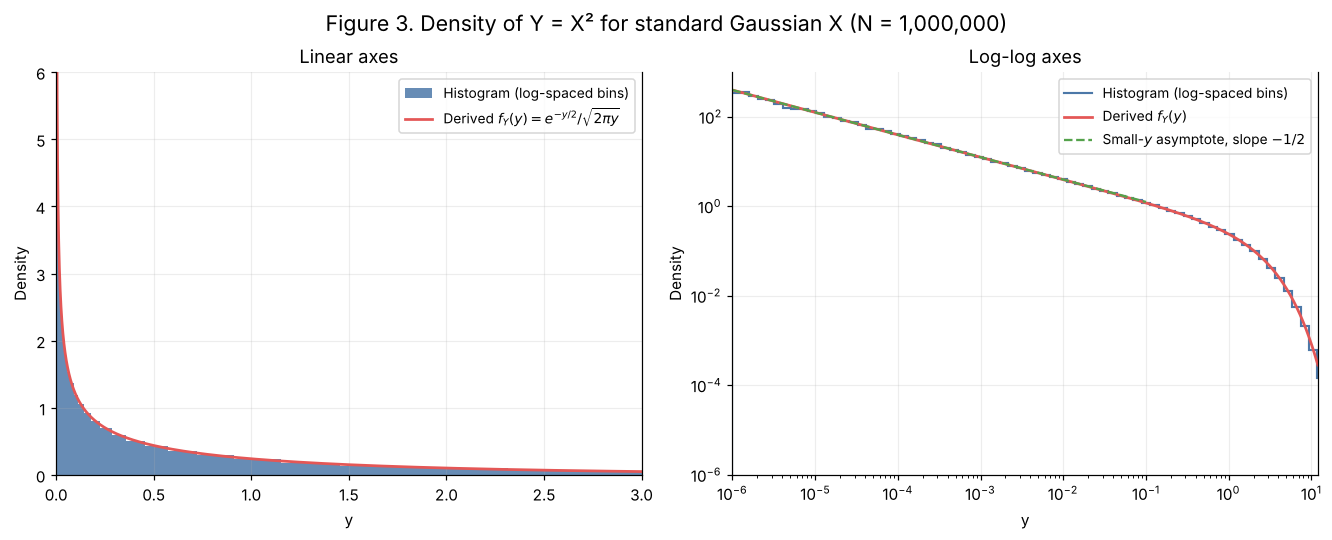

In [6]:
N3 = 1_000_000
critical3 = 1.36 / np.sqrt(N3)
x3 = rng3.standard_normal(N3)
y3 = x3 ** 2
law3 = stats.chi2(1)

def cdf_y(y):
    return 2 * stats.norm.cdf(np.sqrt(y)) - 1

def pdf_y(y):
    return np.exp(-y / 2) / np.sqrt(2 * np.pi * y)

# Density integrates to 1 despite the divergence: y^(-1/2) weight on (0, 1], plain on [1, inf)
from scipy.integrate import quad
head, head_err = quad(lambda y: np.exp(-y / 2) / np.sqrt(2 * np.pi), 0, 1, weight='alg', wvar=(-0.5, 0))
tail, tail_err = quad(pdf_y, 1, np.inf)
integral3 = head + tail
mass_rows = [[f'{d:g}', cdf_y(d), 2 * np.sqrt(d) / np.sqrt(2 * np.pi), pdf_y(d)]
             for d in (1e-1, 1e-2, 1e-4, 1e-6)]

# KS goodness of fit of the squared samples against the derived CDF
d3 = ks_statistic(y3, cdf_y)
d3_lib = ks_statistic(y3, law3.cdf)

# Log-spaced histogram normalized to a density (counts / (N * width))
edges = np.geomspace(1e-6, y3.max(), int(10 * np.log10(y3.max() / 1e-6)) + 1)
counts, _ = np.histogram(y3, bins=edges)
widths = np.diff(edges)
hist_density = counts / (N3 * widths)
centers = np.sqrt(edges[:-1] * edges[1:])
# bin-wise exact density: bin probability / width (what the histogram estimates)
exact_bin_density = np.diff(cdf_y(edges)) / widths

# Empirical log-log slope over bins with y < 0.01 (counts large enough to be reliable)
small = (centers < 1e-2) & (counts >= 30)
slope_fit = np.polyfit(np.log(centers[small]), np.log(hist_density[small]), 1)
slope3 = slope_fit[0]
slope_theory = -0.5

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
grid = np.geomspace(1e-6, 12, 3000)
ax = axes[0]
ax.stairs(hist_density, edges, color='#4c78a8', alpha=.85, fill=True, label='Histogram (log-spaced bins)')
ax.plot(grid, pdf_y(grid), color='#e45756', lw=1.8, label=r'Derived $f_Y(y)=e^{-y/2}/\sqrt{2\pi y}$')
ax.set(title='Linear axes', xlabel='y', ylabel='Density', xlim=(0, 3), ylim=(0, 6))
ax.legend(fontsize=9)
ax = axes[1]
ax.stairs(hist_density, edges, color='#4c78a8', lw=1.4, label='Histogram (log-spaced bins)')
ax.plot(grid, pdf_y(grid), color='#e45756', lw=1.8, label=r'Derived $f_Y(y)$')
ref = grid[grid < 1e-1]
ax.plot(ref, 1 / np.sqrt(2 * np.pi * ref), '--', color='#54a24b', lw=1.5,
        label=r'Small-$y$ asymptote, slope $-1/2$')
ax.set(title='Log-log axes', xlabel='y', ylabel='Density', xscale='log', yscale='log',
       xlim=(1e-6, 12), ylim=(1e-6, 1e3))
ax.legend(fontsize=9)
fig.suptitle('Figure 3. Density of Y = X² for standard Gaussian X (N = 1,000,000)', fontsize=14)

# Probabilities, median, mean, variance with standard errors
m_theory = stats.norm.ppf(0.75) ** 2
rows3 = []
for name, thr in [('P[Y ≤ 1]', 1.0), ('P[Y ≤ 0.1]', 0.1)]:
    p = cdf_y(thr)
    est = np.mean(y3 <= thr)
    se = np.sqrt(p * (1 - p) / N3)
    rows3.append([name, est, p, est - p, se, (est - p) / se])
m_est = np.median(y3)
se_m = 1 / (2 * pdf_y(m_theory) * np.sqrt(N3))
rows3.append(['Median', m_est, m_theory, m_est - m_theory, se_m, (m_est - m_theory) / se_m])
mean_est, var_est = y3.mean(), y3.var(ddof=1)
se_mean = np.sqrt(2 / N3)
se_var = np.sqrt((60 - 2 ** 2) / N3)
rows3.append(['Mean', mean_est, 1.0, mean_est - 1, se_mean, (mean_est - 1) / se_mean])
rows3.append(['Variance', var_est, 2.0, var_est - 2, se_var, (var_est - 2) / se_var])

print(f'Density integral: {head:.10f} on (0,1] + {tail:.10f} on [1,inf) = {integral3:.10f}')
table(['δ', 'Exact P(Y ≤ δ)', 'Approx 2√δ/√(2π)', 'f_Y(δ)'], mass_rows)
table(['Test', 'N', 'KS D vs derived CDF', '95% cutoff', 'KS D vs scipy chi2(1)', 'Decision'],
      [['Y = X²', N3, d3, critical3, d3_lib, 'Do not reject' if d3 < critical3 else 'Reject']])
table(['Quantity', 'Empirical', 'Theory', 'Difference', 'Std. error', 'Diff / SE'], rows3)
table(['Log-log slope (y < 0.01)', 'Fitted', 'Theory', 'Difference'],
      [['Histogram', slope3, slope_theory, slope3 - slope_theory]])
finish(fig, 'figure_03')

Figure 3 overlays the density-normalized histogram on the derived $f_Y$. The left panel shows the spike at the origin and the rapid decay by $y\approx3$; the right panel shows the same data on log-log axes, where the divergence is a straight line. The log-spaced bins, 10 per decade from $10^{-6}$, resolve the region near zero that a uniform width of 0.5 would collapse into a single bar. The fitted histogram slope for $y<0.01$ is **-0.4959**, against the theoretical **-1/2**; the slope comes from the Jacobian $1/(2\sqrt y)$ of the inverse map $x=\sqrt y$, i.e. the flat squaring map compressing probability near $x=0$.

The density integrates to **1.0000000000** numerically (**0.6826895** on $(0,1]$ plus **0.3173105** on $[1,\infty)$), so the divergence is integrable. The mass inside $[0,\delta]$ shrinks like $2\sqrt{\delta/(2\pi)}$ (**0.0007979** at $\delta=10^{-6}$) even though $f_Y(10^{-6})=$ **398.94**. The KS distance to the derived CDF is **D = 0.0009189**, below the 95% cutoff **0.00136**, so the sample does not reject $F_Y$. As before, this decision applies to the frozen seed.

All five quantities are within **one standard error** of theory (|difference/SE| ≤ **0.97**), using $N=10^6$ trials: $P[Y\leq1]=$ **0.682239** (theory 0.6826895, SE 0.000465), $P[Y\leq0.1]=$ **0.248191** (theory 0.2481704, SE 0.000432), median **0.455406** (theory 0.4549364), mean **1.000613**, variance **1.994066**. The median **0.4549** is less than half the mean **1**: the unbounded density at the origin packs much of the probability near zero, while the long right tail (the squares of large Gaussians) pulls the mean up.

In [7]:
# Numerical conclusions for Steps 1–3.
for row in rows1 + rows2:
    print(f'{row[0]}: D = {row[2]:.7f}, cutoff = {row[3]:.7f}: {row[4]}')
for row in comparison_rows2:
    print(f'{row[0]}, inversion vs library: D = {row[2]:.7f}, '
          f'cutoff = {row[3]:.7f}: {row[4]}')
print(f'Step 3: density integral = {integral3:.10f}; KS D = {d3:.7f}, cutoff = {critical3:.7f}: '
      f"{'Do not reject' if d3 < critical3 else 'Reject'}")
for row in rows3:
    print(f'Step 3 {row[0]}: estimate = {row[1]:.7g}, theory = {row[2]:.7g}, SE = {row[4]:.3g}, z = {row[5]:.2f}')
print(f'Step 3 log-log slope: fitted {slope3:.4f}, theory {slope_theory}')

Uniform [0,1]: D = 0.0033703, cutoff = 0.0043007: Do not reject
Exponential, rate 1: D = 0.0017654, cutoff = 0.0043007: Do not reject
Standard Gaussian: D = 0.0034542, cutoff = 0.0043007: Do not reject
Rayleigh, scale 1: D = 0.0024282, cutoff = 0.0043007: Do not reject
Exponential, rate 1: D = 0.0038259, cutoff = 0.0043007: Do not reject
Rayleigh, scale 1: D = 0.0020791, cutoff = 0.0043007: Do not reject
Exponential, rate 1, inversion vs library: D = 0.0042500, cutoff = 0.0060821: Do not reject
Rayleigh, scale 1, inversion vs library: D = 0.0041700, cutoff = 0.0060821: Do not reject
Step 3: density integral = 1.0000000000; KS D = 0.0009189, cutoff = 0.0013600: Do not reject
Step 3 P[Y ≤ 1]: estimate = 0.682239, theory = 0.6826895, SE = 0.000465, z = -0.97
Step 3 P[Y ≤ 0.1]: estimate = 0.248191, theory = 0.2481704, SE = 0.000432, z = 0.05
Step 3 Median: estimate = 0.4554059, theory = 0.4549364, SE = 0.00106, z = 0.44
Step 3 Mean: estimate = 1.000613, theory = 1, SE = 0.00141, z = 0.43
S

In [8]:
TOTAL_RUNTIME = perf_counter() - START
print(f'Completed scope: Steps 1–3 only. Runtime: {TOTAL_RUNTIME:.2f} seconds.')
print('Steps 4–8 remain pending; remeasure the complete notebook before submission.')

Completed scope: Steps 1–3 only. Runtime: 8.28 seconds.
Steps 4–8 remain pending; remeasure the complete notebook before submission.
